# Phase 2 — Image Processing and Rectification

Goals:

- learn the OpenCV image representation and coordinate system;
- rectify MIDV photographs using ground-truth `doc_quad`;
- normalize `alb_id` into a canonical image size;
- map template field geometry into canonical coordinates;
- crop the seven required fields;
- implement and calibrate controlled image degradations.

In [2]:
from pathlib import Path
import json

import cv2
import numpy as np
import matplotlib.pyplot as plt

Let's use the same doctype and image from the previous notebook.

In [8]:
current_directory = Path.cwd().resolve()
if (current_directory / "PROJECT.md").exists():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").exists():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks directory.")

DATASET_ROOT = repository_root / "data/raw"

DOC_TYPE = "alb_id"
SAMPLE_ID = "00.jpg"

template_image_path = DATASET_ROOT / "templates/images" / DOC_TYPE / SAMPLE_ID
photo_image_path = DATASET_ROOT / "photo/images" / DOC_TYPE / SAMPLE_ID

if not photo_image_path.is_file():
    raise FileNotFoundError(photo_image_path)



(PosixPath('/home/raspiestchip/kyc-router/data/raw/templates/images/alb_id/00.jpg'),
 PosixPath('/home/raspiestchip/kyc-router/data/raw/photo/images/alb_id/00.jpg'))

Now let's load the photograph with OpenCV

In [9]:
image_bgr = cv2.imread(str(photo_image_path))

assert image_bgr is not None

print(type(image_bgr))
print(image_bgr.dtype)
print(image_bgr.shape)

<class 'numpy.ndarray'>
uint8
(4032, 2268, 3)


`cv2.imread()` does not return some special `Image` class. You get a regular NumPy array.

For `image_bgr.shape` the convention is `(height, width, channels)`.

That's really important to understand now, a point `(x,y)` means:
```
x = horizontal position = column
y = vertical position = row
```
But direct NumPy indexing means `image[y,x]`

Let's inspect one pixel:

In [11]:
y = 400
x = 200

pixel = image_bgr[y, x]

print(pixel)

[137 121  79]


One more caveat: `OpenCV's` default channel order is B,G,R rather than R,G,B.

Look what happens when we display the image in matplotlib (which uses R,G,B ordering).

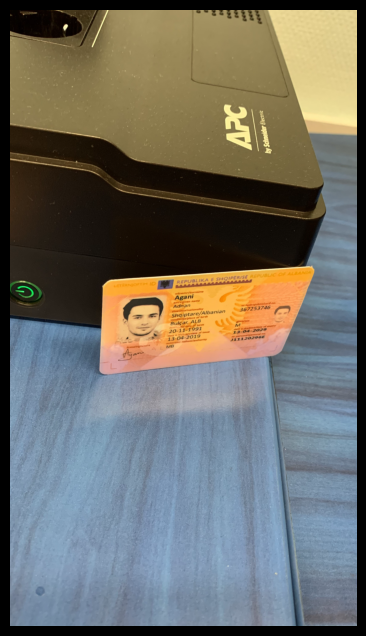

In [12]:
plt.figure(figsize=(8, 8))
plt.imshow(image_bgr)
plt.axis("off")
plt.show()

Weird colors! Let's fix it.

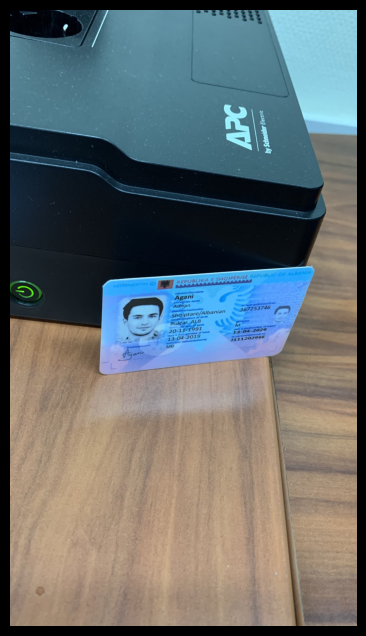

In [13]:
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

Back to normal.

In [15]:
print(image_bgr.dtype)
print(image_bgr.shape)
print(photo_image_path)

uint8
(4032, 2268, 3)
/home/raspiestchip/kyc-router/data/raw/photo/images/alb_id/00.jpg


## Coordinates and Basic Image Operations

Let's make the image's dimensions explicit

In [16]:
height, width = image_bgr.shape[:2]

print("width:", width)
print("height:", height)

width: 2268
height: 4032


Let's put a marker exactly at the center of the photograph

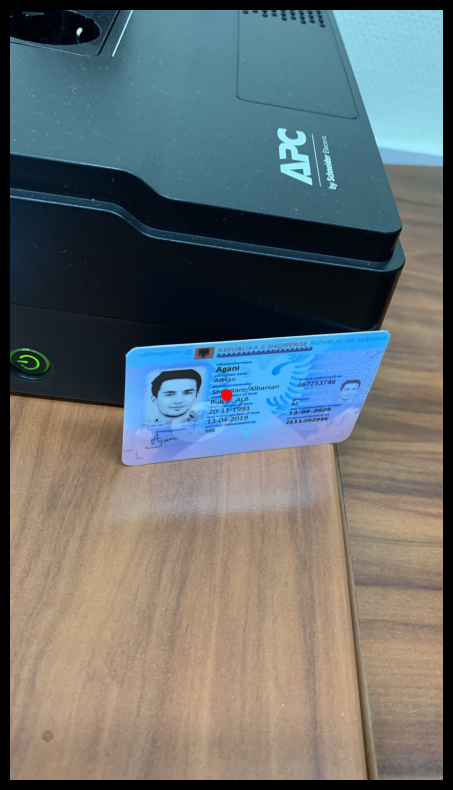

In [18]:
center_x = width // 2
center_y = height // 2

debug_image = image_bgr.copy()

cv2.circle(
    debug_image,
    (center_x, center_y),
    radius=30,
    color=(0, 0, 255),
    thickness=-1,
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(debug_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Notice the `copy()`.

Functions such as:
```python
cv2.circle()
cv2.rectangle()
cv2.line()
```
Modify the NumPy array you give them in place. If we drew directly onto `image_bgr`, we'd be modifying our working input.

### Grayscale


(4032, 2268)
uint8


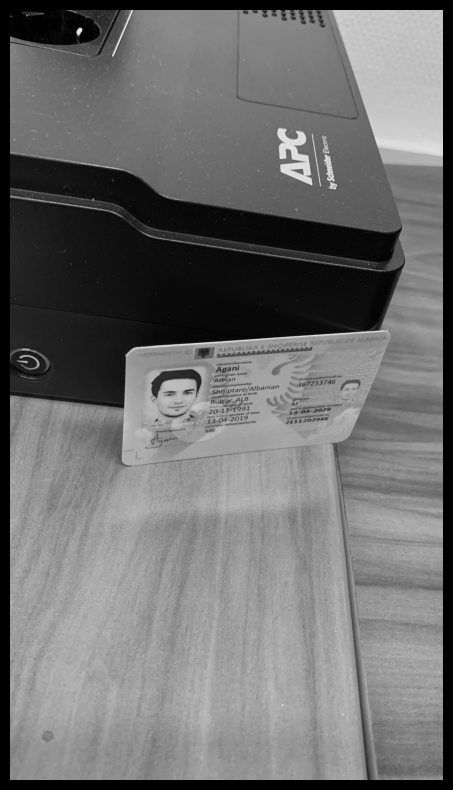

In [19]:
gray_image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

print(gray_image.shape)
print(gray_image.dtype)

plt.figure(figsize=(8, 10))
plt.imshow(gray_image, cmap="gray")
plt.axis("off")
plt.show()

We've gone from three values per pixel to one intensity, roughly representing brightness.

This matters because quite a few classical CV algorithms don't actually need color. Later things such as edge detection, Laplacian sharpness measurement, thresholding, and contour detection will commonly operate on grayscale images.

For our project, one of the router features we've already specified is variance of the grayscale Laplacian as a cheap sharpness measurement, so this isn't just an OpenCV tutorial detour—it returns later in the actual experiment.

### Resizing

In [20]:
small_image = cv2.resize(
    image_bgr,
    (width // 4, height // 4),
)

print("original:", image_bgr.shape)
print("resized:", small_image.shape)

original: (4032, 2268, 3)
resized: (1008, 567, 3)


`cv2.resize()` expects (width, height). While NumPy shape reports (height, width, channels). So, `cv2.resize(image, (567,1008))` produces `shape = (1008, 567, 3)`.

Now look at the size difference:


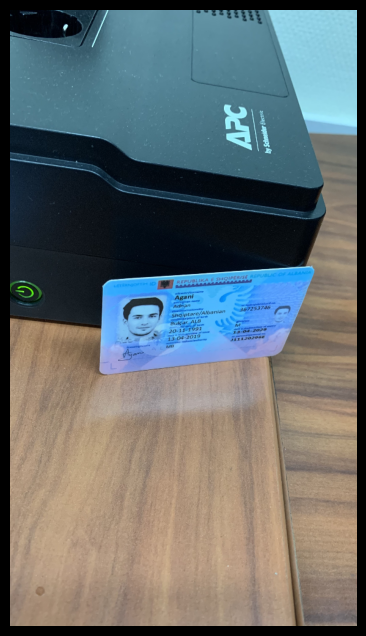

In [21]:
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Downscale Degradation
Look what happens when we agressively resize the image down and then enlarge it back:

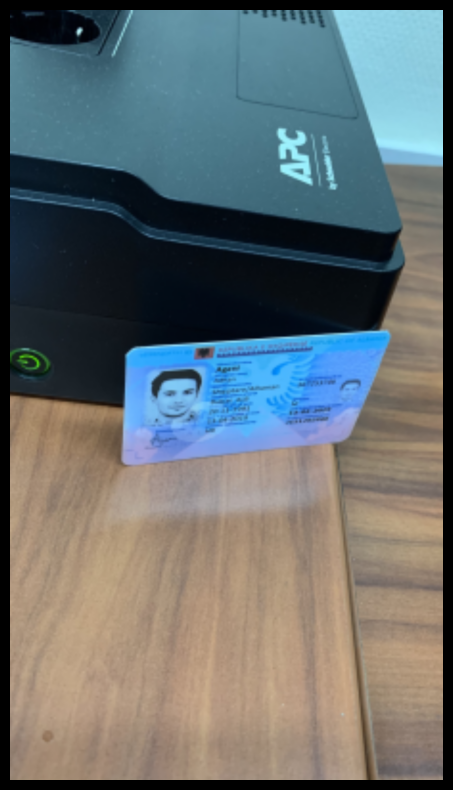

In [22]:
tiny = cv2.resize(
    image_bgr,
    (width // 10, height // 10),
    interpolation=cv2.INTER_AREA,
)

restored = cv2.resize(
    tiny,
    (width, height),
    interpolation=cv2.INTER_LINEAR,
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(restored, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

The final array once again contains millions of pixels, but the information destroyed during downsampling is gone.

## Document quadrilateral

MIDV photo annotations contain a `doc_quad` polygon describing the four
corners of the physical document in the photograph.

Before performing perspective rectification, we will:

1. retrieve the polygon from the VIA annotation;
2. represent its vertices as a NumPy array;
3. draw and label the vertices;
4. inspect the geometry of its four edges.

Let's inspect the photo regions. (I've done a more detailed investigation on notebook one!)

In [30]:
photo_annotation_path = DATASET_ROOT / "photo" / "annotations" / "alb_id.json"

with open(photo_annotation_path, "r", encoding="utf-8") as f:
    photo_annotations = json.load(f)

metadata = photo_annotations["_via_img_metadata"]

filename = photo_image_path.name

photo_record = None

for record in metadata.values():
    if record["filename"] == filename:
        photo_record = record
        break

for region in photo_record["regions"]:
    print(region["region_attributes"])

{'field_name': 'face', 'value': '', 'features': {}}
{'field_name': 'doc_quad'}


We will draw the same doc_quad region from the previous notebook, but this time using `openCV`.

In [32]:
doc_quad_region = None

for region in photo_record["regions"]:
    field_name = region["region_attributes"].get("field_name")

    if field_name == "doc_quad":
        doc_quad_region = region
        break

doc_quad_shape = doc_quad_region["shape_attributes"]

x_coordinates = doc_quad_shape["all_points_x"]
y_coordinates = doc_quad_shape["all_points_y"]

document_corners = np.array(
    list(zip(x_coordinates, y_coordinates)),
    dtype=np.float32,
)

print(document_corners)
print(document_corners.shape)
print(document_corners.dtype)

[[ 613. 1767.]
 [2007. 1674.]
 [1769. 2260.]
 [ 581. 2395.]]
(4, 2)
float32


Drawing the actual quadrilateral

In [34]:
annotated_photo = image_bgr.copy()

corners_int = document_corners.astype(np.int32) # OpenCV drawing functions generally prefer Integer coordinates

For Polygons, OpenCV expects and extra dimension.

In [35]:
polygon = corners_int.reshape((-1, 1, 2))

print(corners_int.shape)
print(polygon.shape)

(4, 2)
(4, 1, 2)


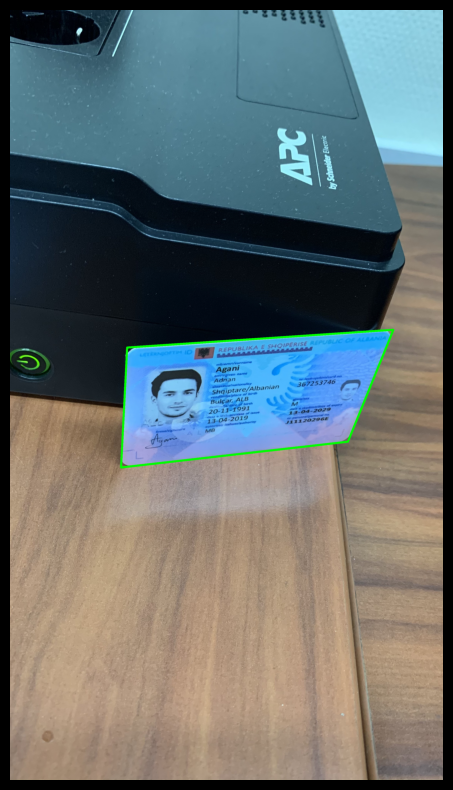

In [36]:
cv2.polylines(
    annotated_photo,
    [polygon],
    isClosed=True,
    color=(0, 255, 0),
    thickness=10,
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(annotated_photo, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Let's inspect the distances between those points.

In [37]:
top_width = np.linalg.norm(document_corners[1] - document_corners[0])
bottom_width = np.linalg.norm(document_corners[2] - document_corners[3])

left_height = np.linalg.norm(document_corners[3] - document_corners[0])
right_height = np.linalg.norm(document_corners[2] - document_corners[1])

print(f"top width:     {top_width:.2f}")
print(f"bottom width:  {bottom_width:.2f}")
print(f"left height:   {left_height:.2f}")
print(f"right height:  {right_height:.2f}")

top width:     1397.10
bottom width:  1195.65
left height:   628.81
right height:  632.49


`document_corners[1] - document_corners[0]` computes the vector $(x_1 - x_0, y_1 - y_0)$

And `np.linalg.norm(...)` computes its euclidean length:
$\sqrt{(x_1 - x_0)^2 + (y_1 - y_0)^2}$


Notice that the top width != bottom width. That's perspective. And we're going to be solving that with rectification. The goal is:
> Find a transformation that maps these four known source points onto the four corners of a rectangle.